# Optimizer Step · PyTorch Episode 11
## Transfer learning: a borrowed brain for our shop

Episode 10 ended on a question: an 18-layer model that has already studied 12.8 lakh photos. Can it help our shop? Today we test it. First, what it says about our photos before one step of training on them. Then a new shop with 10,000 practice photos, a fifth of ours: a blank brain races the borrowed one, with Episode 8's CNN as the target. Then inside the borrowed brain: what it learned from ImageNet, and what happens when we freeze it and train only a new head. Then the research lab: five silent mistakes with borrowed brains.

| Word | Meaning | In shop terms |
|---|---|---|
| ImageNet | 12.8 lakh practice photos on 1,000 shelves (the set ResNet18 studied) | a giant store |
| borrowed brain (pretrained) | a model whose knobs already studied another set of photos | an experienced employee from the giant store |
| transfer learning | start from those knobs, then study our own photos | hire that employee, teach them our shelves |
| head | the last `Linear` layer: 512 numbers in, one score per shelf out | the shelf labels |
| fingerprint | the 512 numbers just before the head | the employee's notes on one photo |
| freeze | `requires_grad = False`: those knobs don't move | the habits stay; only the new labels are learned |

Every seed is 42 and the GPU runs in deterministic mode. Run the cells in order. Keep `ep11_plots.py`, `cnn_model.pt` and the `data` folder next to this notebook. The ResNet18 weights are already on this laptop.

### 1 · Tools
Two new imports: `models` (ResNet18) and `v2` (photo transforms). The last lines check that the photos, Episode 8's CNN and the ResNet18 weights are already on this laptop, so nothing needs downloading.

In [1]:
import copy
from pathlib import Path
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, models
from torchvision.transforms import v2
import ep11_plots as viz                   # drawing helpers only

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.deterministic = True  # same numbers every run
torch.backends.cudnn.benchmark = False
need = [Path("data/FashionMNIST"), Path("cnn_model.pt"),
        Path(torch.hub.get_dir()) / "checkpoints/resnet18-f37072fd.pth"]
for p in need:                             # all on this laptop already
    assert p.exists(), f"missing {p}: see the PDF"
print(torch.__version__, "|", device)

2.13.0+cu130 | cuda


### 2 · The photos
The same 70,000 photos and the same split as Episodes 7 to 10.

In [2]:
train_set = datasets.FashionMNIST("data", train=True, download=False)
test_set = datasets.FashionMNIST("data", train=False, download=False)
classes = train_set.classes
X = train_set.data.float().unsqueeze(1) / 255   # 1 channel: grey
y = train_set.targets
X_train, y_train = X[:50000], y[:50000]    # practice book
X_val, y_val = X[50000:], y[50000:]        # mock test
X_test = test_set.data.float().unsqueeze(1) / 255   # board exam
y_test = test_set.targets
print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([50000, 1, 28, 28]) torch.Size([10000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


### 3 · Grading, 500 photos at a time
Episode 10's helpers. ResNet18 is bigger, so the GPU grades 500 photos at a time instead of 1,000.

In [3]:
def picks(model, X):                       # the shelf it picks, per photo
    model.eval()                           # exam mode
    out = []
    with torch.no_grad():
        for i in range(0, len(X), 500):    # 500 photos at a time
            scores = model(X[i:i + 500].to(device))
            out.append(scores.argmax(dim=1).cpu())
    return torch.cat(out)

def accuracy(model, X, y):
    return round((picks(model, X) == y).float().mean().item(), 3)

## Act 1 · The borrowed brain

### 4 · The borrowed brain
ResNet18 with the knobs it learned from ImageNet: 12.8 lakh practice photos on 1,000 shelves. It loads from this laptop.

**Guess first:** how many knobs? Episode 8's CNN had 20,490.

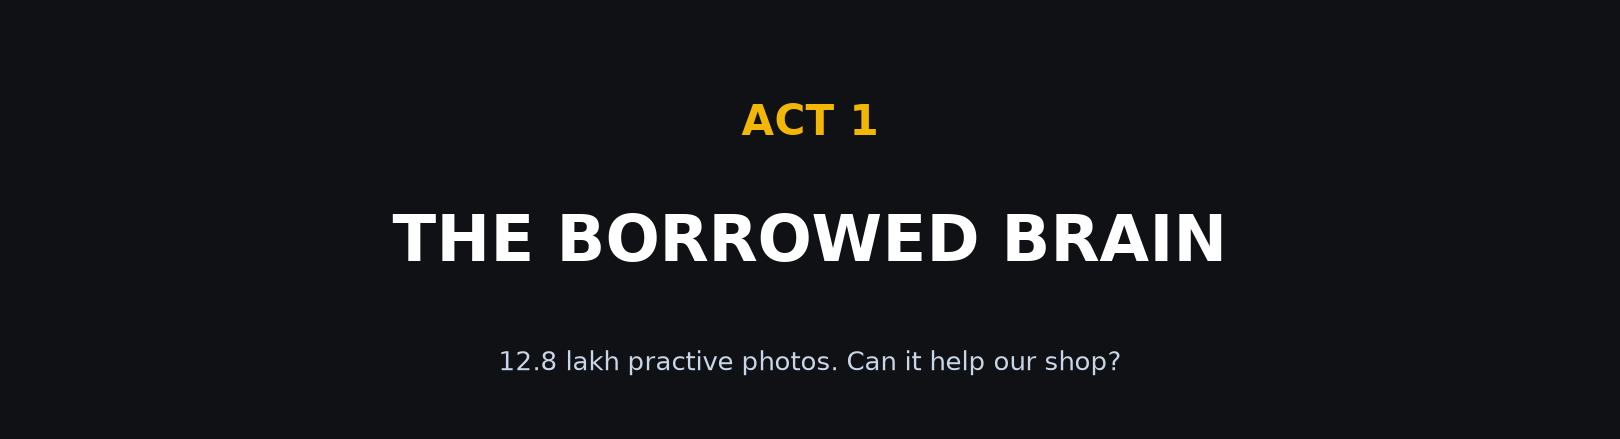

knobs:  11,689,512
Last layer:  Linear(in_features=512, out_features=1000, bias=True)


In [6]:
viz.act(1, "The borrowed brain",
        "12.8 lakh practive photos. Can it help our shop?")

imagenet = models.resnet18(weights="IMAGENET1K_V1")   # from the laptop    # from the laptop
print("knobs: ", f"{sum(p.numel() for p in imagenet.parameters()):,}")
print("Last layer: ", imagenet.fc)


### 5 · The adapter: our photo, the way ImageNet's photos looked
Four steps: flip the colours back (Fashion-MNIST negated them), bigger, grey to 3 colours, and ImageNet's own scale (the six numbers that come with the weights). ImageNet's photos were 224 x 224; to study our shop fast, we use 112.

torch.Size([1, 1, 28, 28]) -> torch.Size([1, 3, 112, 112])


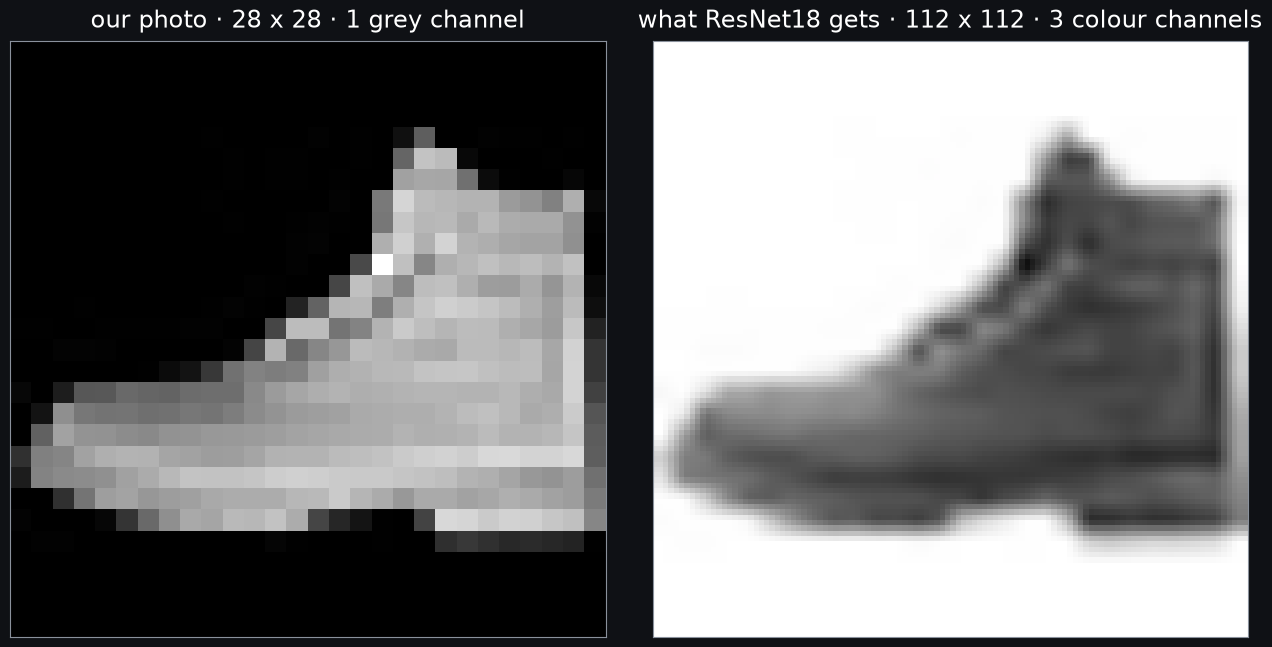

In [7]:
MEAN = [0.485, 0.456, 0.406]               # ImageNet's average colours
STD = [0.229, 0.224, 0.225]                # and their spreads

def flip(x):                               # Fashion-MNIST negated them
    return 1 - x                           # back: dark product on white

def adapter(size):                         # our photo, ImageNet's look
    return nn.Sequential(
        v2.Lambda(flip),
        v2.Resize(size),                   # 28 -> size x size pixels
        v2.RGB(),                          # 1 grey channel -> 3
        v2.Normalize(MEAN, STD),           # ImageNet's own scale
    )

to_imagenet = adapter(112)                 # to study: 4x bigger, fast
photo = X_val[:1]
print(photo.shape, "->", to_imagenet(photo).shape)
viz.show_adapter(photo, to_imagenet(photo), MEAN, STD)

### 6 · What does it see in our shop?
No training on our photos yet. It can only answer with its own 1,000 shelves. To ask what it sees, we show each photo at its own size, 224 x 224.

**Chat picks a photo:** 0 to 9999.

1000 ImageNet shelves. The first three: ['tench', 'goldfish', 'great white shark']
T-shirt/top -> [('jersey', '99.4%'), ('espresso maker', '0.3%'), ('sweatshirt', '0.1%')]


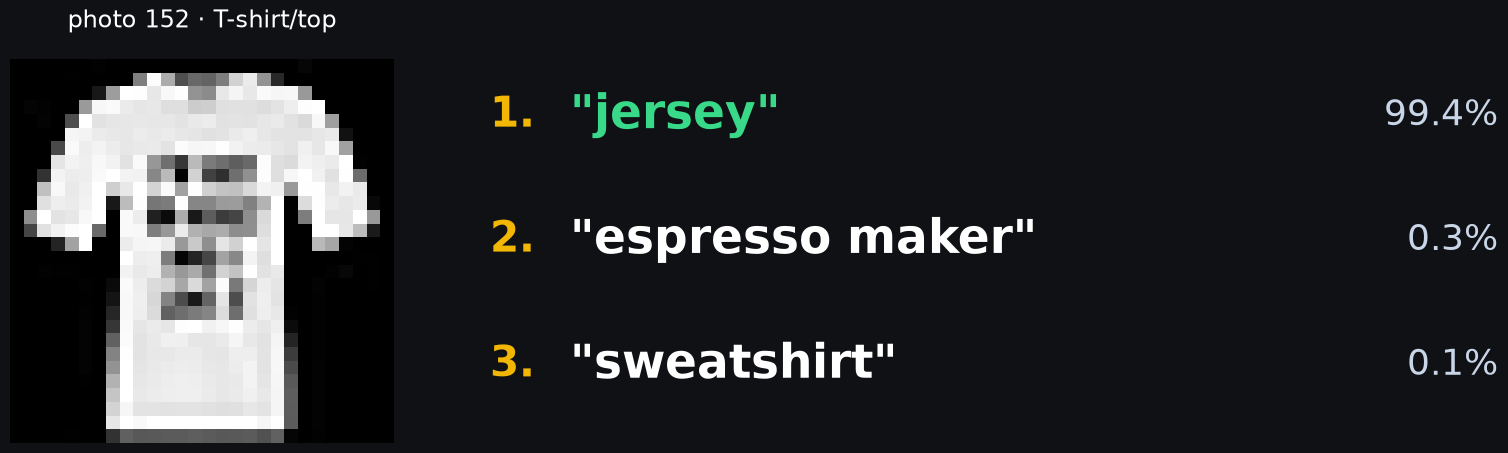

In [8]:
names = models.ResNet18_Weights.IMAGENET1K_V1.meta["categories"]
eyes = nn.Sequential(adapter(224), imagenet).to(device)  # its own size
print(len(names), "ImageNet shelves. The first three:", names[:3])

i = 152                                    # chat picks: 0 to 9999
eyes.eval()
with torch.no_grad():
    scores = eyes(X_val[i:i + 1].to(device))[0]          # 1,000 scores
chances = torch.softmax(scores, dim=0).cpu()
best3 = chances.topk(3)                    # its three favourite shelves
guesses = [(names[k], c.item())
           for c, k in zip(best3.values, best3.indices)]
print(classes[y_val[i]], "->", [(n, f"{c:.1%}") for n, c in guesses])
viz.show_guesses(X_val[i], guesses, f"photo {i} · {classes[y_val[i]]}")

### 7 · The whole mock test, shelf by shelf
For each of our shelves, its favourite ImageNet shelf, out of 10,000 photos.

**Guess first:** what does it call our trousers?

('T-shirt/top', 'jersey', 647, 1023)
('Trouser', 'can opener', 492, 988)
('Pullover', 'sweatshirt', 412, 1008)
('Dress', 'can opener', 148, 1021)
('Coat', 'sweatshirt', 431, 1050)
('Sandal', 'can opener', 234, 996)
('Shirt', 'sweatshirt', 386, 970)
('Sneaker', 'clog', 480, 955)
('Bag', 'mailbag', 318, 968)
('Ankle boot', 'clog', 607, 1021)


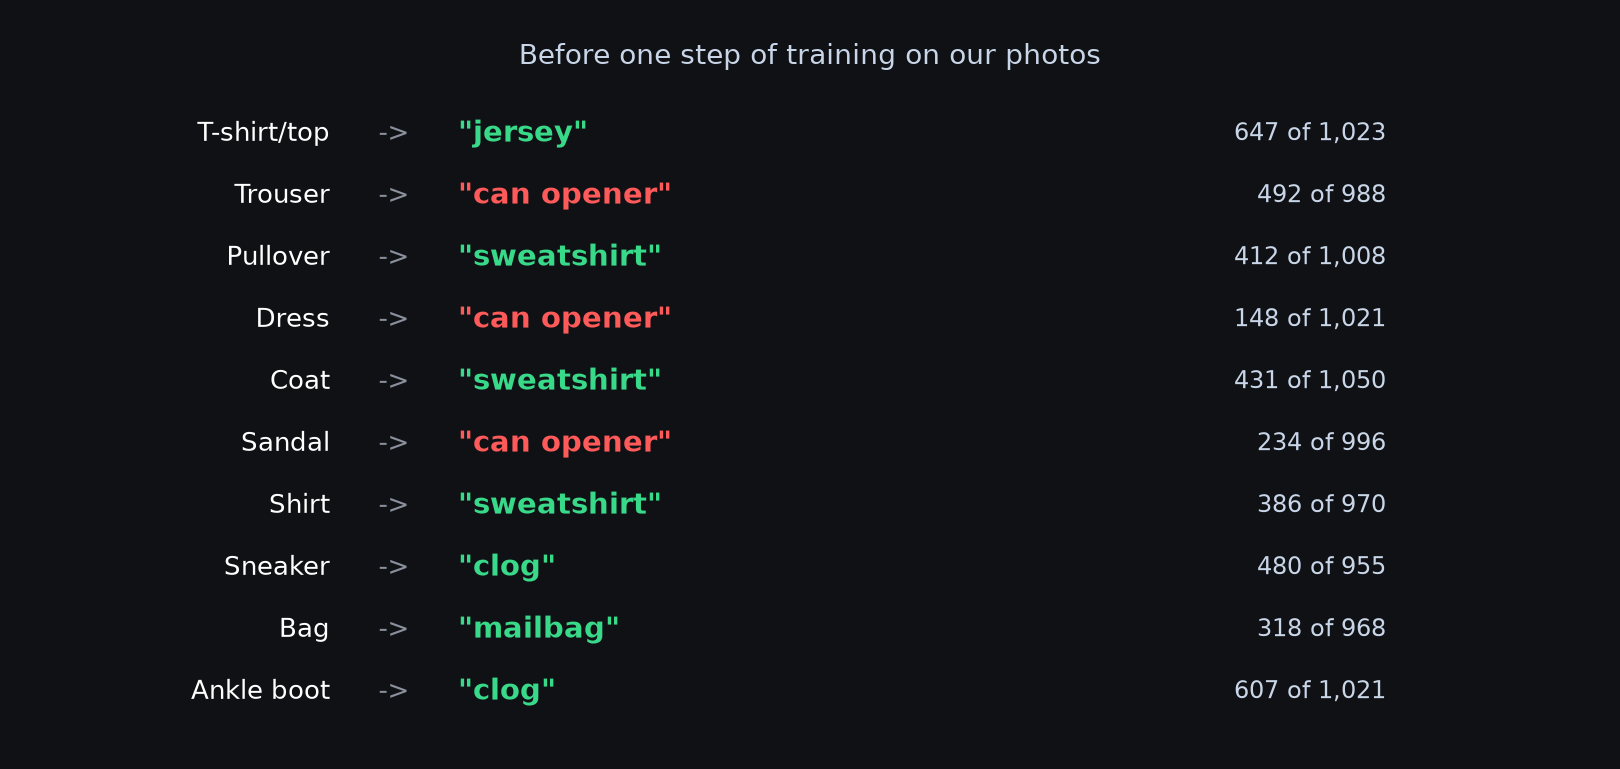

In [10]:
guess = picks(eyes, X_val)
rows = []
for s, shelf in enumerate(classes):
    counts = torch.bincount(guess[y_val == s], minlength = 1000)
    k = int(counts.argmax())
    rows.append((shelf, names[k], int(counts[k]), int(counts.sum())))
    print(rows[-1])
viz.show_shelf_guesses(rows, "Before one step of training on our photos")


### 8 · Two brains and a new shop
The borrowed brain keeps ImageNet's knobs and gets a new head with our 10 shelves. The blank brain has the same shape, with random knobs. The new shop has 1,000 photos per shelf: 10,000, a fifth of our practice book.

In [11]:
def borrowed_brain():                      # ImageNet's knobs, a new head
    body = models.resnet18(weights="IMAGENET1K_V1")
    body.fc = nn.Linear(512, 10)           # our 10 shelves, not 1,000
    return nn.Sequential(to_imagenet, body).to(device)

def blank_brain():                         # the same shape, random knobs
    body = models.resnet18(weights=None)
    body.fc = nn.Linear(512, 10)
    return nn.Sequential(to_imagenet, body).to(device)

def shop(k):                               # the first k photos per shelf
    idx = torch.cat([torch.nonzero(y_train == s)[:k, 0]
                     for s in range(10)])
    return X_train[idx], y_train[idx]

X_shop, y_shop = shop(1000)                # a new shop: 10,000 photos
knobs = sum(p.numel() for p in blank_brain().parameters())
print(X_shop.shape, "|", f"{knobs:,} knobs in each brain")

torch.Size([10000, 1, 28, 28]) | 11,181,642 knobs in each brain


### 9 · One study function
Adam, batches of 64, a snapshot of the best mock test, and a mock test every 50 batches, drawn live. One change from Episodes 7 to 10: smaller steps, `lr=0.0001`, for **both** brains. A borrowed brain needs them (Act 3 shows why).

In [12]:
loss_fn = nn.CrossEntropyLoss()

def study(model, name, X, y, epochs=3, lr=0.0001, every=50):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X, y), batch_size=64, shuffle=True)
    curve, seen, done, step, best_acc = [], [], 0, 0, 0
    for epoch in range(epochs):
        for xb, yb in loader:
            model.train()                  # study mode
            loss = loss_fn(model(xb.to(device)), yb.to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            done, step = done + len(xb), step + 1
            if step % every == 0:          # a mock test every 50 batches
                curve.append(accuracy(model, X_val, y_val))
                seen.append(done)
                viz.race_chart(name, seen, curve, epochs * len(X))
                if curve[-1] > best_acc:   # new best: snapshot
                    best_acc = curve[-1]
                    best = copy.deepcopy(model.state_dict())
    model.load_state_dict(best)            # back to the best mock test
    return curve

### 10 · The target: Episode 8's CNN
It studied all 50,000 photos (it's in `cnn_model.pt`). Its mock test becomes a gold line on the race chart.

In [13]:
def new_cnn():                             # Episode 8's CNN, 20,490 knobs
    return nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(32 * 7 * 7, 10),
    )

ep8 = new_cnn().to(device)                 # it studied all 50,000 photos
ep8.load_state_dict(torch.load("cnn_model.pt", map_location=device))
ep8_mock = accuracy(ep8, X_val, y_val)
print("Episode 8's CNN · mock test:", ep8_mock)
viz.race_target(ep8_mock, "Episode 8's CNN · 50,000 photos")

Episode 8's CNN · mock test: 0.916


### 11 · The race: blank brain against borrowed brain
The same 10,000 photos, the same recipe, 3 epochs each. The only difference: the knobs they start with.

**The poll:** does the borrowed brain reach Episode 8's gold line, with a fifth of the photos?

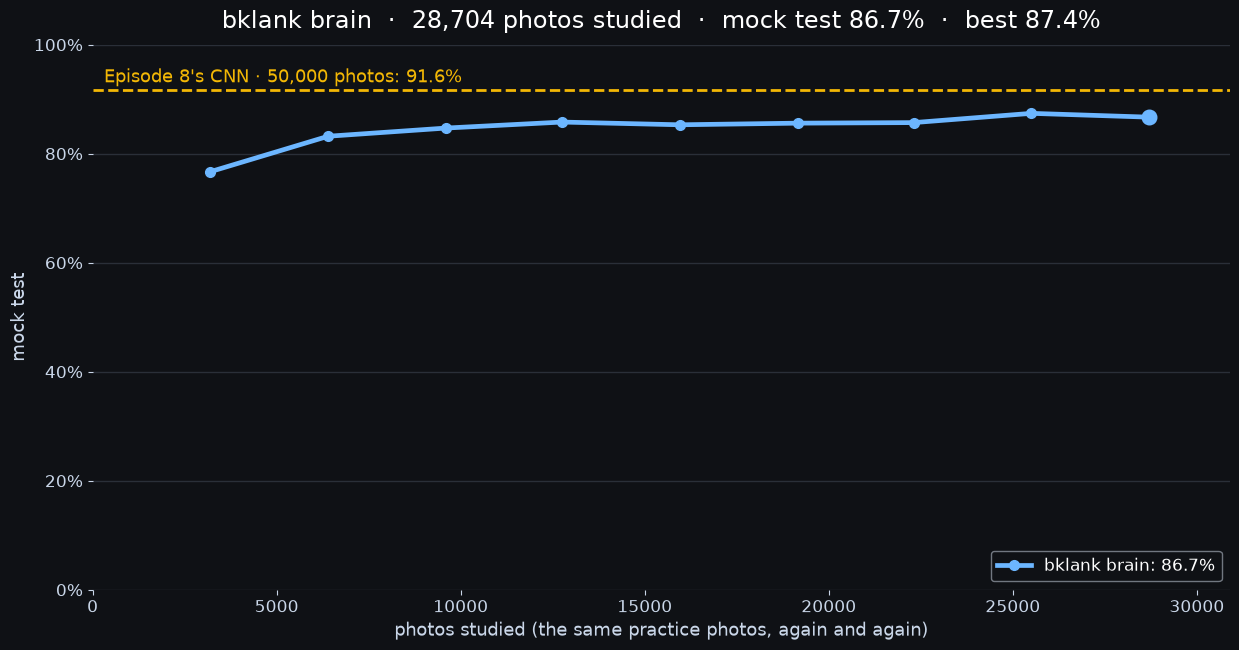

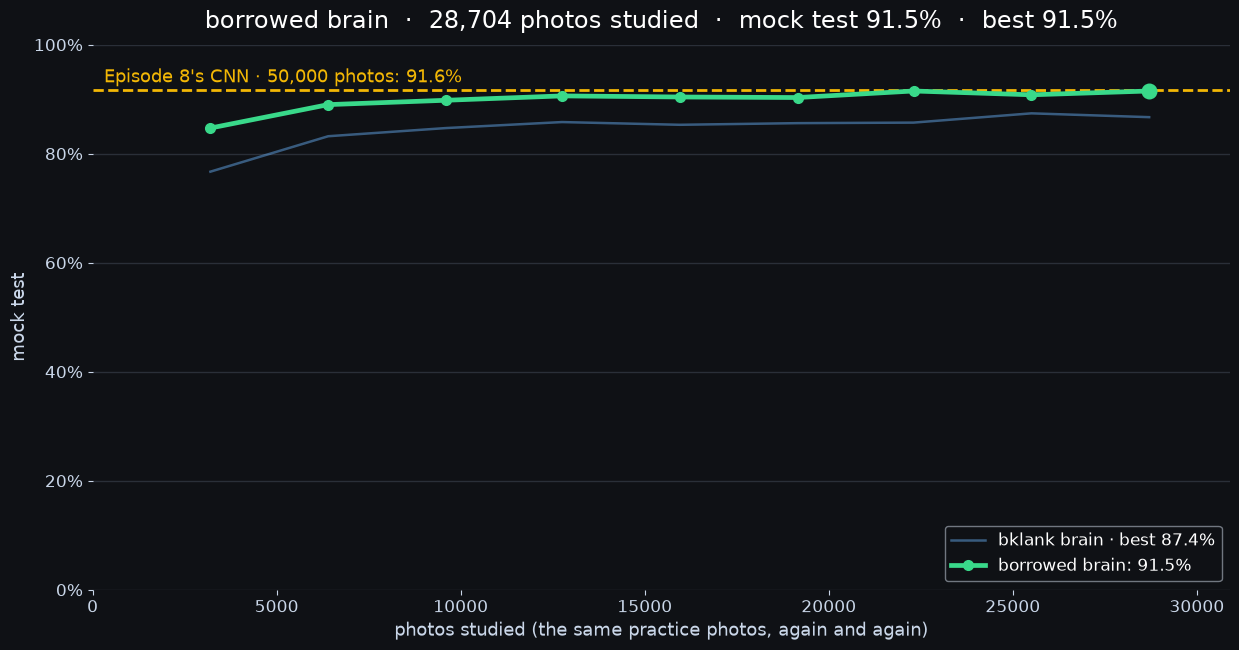

forst mock test blank:  0.767 | borrowed:  0.847
Best mock test:  0.874 0.915


In [14]:
torch.manual_seed(42)
blank = blank_brain()
blank_curve = study(blank, "bklank brain", X_shop, y_shop)
torch.manual_seed(42)
borrowed = borrowed_brain()
borrowed_curve = study(borrowed, "borrowed brain", X_shop, y_shop)
print("forst mock test blank: ", blank_curve[0],
      "| borrowed: ", borrowed_curve[0])
print("Best mock test: ", max(blank_curve), max(borrowed_curve))

### 12 · The board exam
Each brain at its best mock test, against Episode 8's CNN.

Board exam: Ep 8's CNN model ->  0.906 Blank brain board exam ->  0.868 Borrowed brain: RESNET 18 ->  0.913


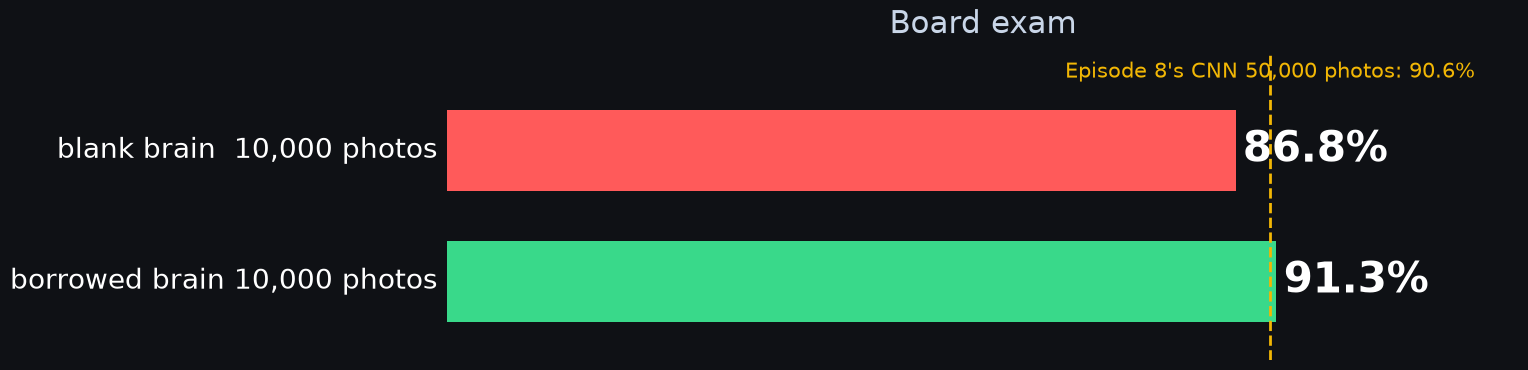

In [16]:
ep8_board = accuracy(ep8, X_test, y_test)
blank_board = accuracy(blank, X_test, y_test)
borrowed_board = accuracy(borrowed, X_test, y_test)
print("Board exam: Ep 8's CNN model -> ", ep8_board,
      "Blank brain board exam -> ", blank_board,
       "Borrowed brain: RESNET 18 -> ", borrowed_board)
viz.reveal_board([("blank brain  10,000 photos", blank_board, viz.HOT),
                  ("borrowed brain 10,000 photos", borrowed_board, viz.NEON)],
                  "Board exam", target = ep8_board,
                  target_label = "Episode 8's CNN 50,000 photos")

## Act 2 · What did it borrow?

### 13 · Layer 1's 64 windows
ResNet18's first layer: 64 windows of 7 x 7 pixels, in 3 colours. Borrowed from ImageNet, next to a blank brain's.

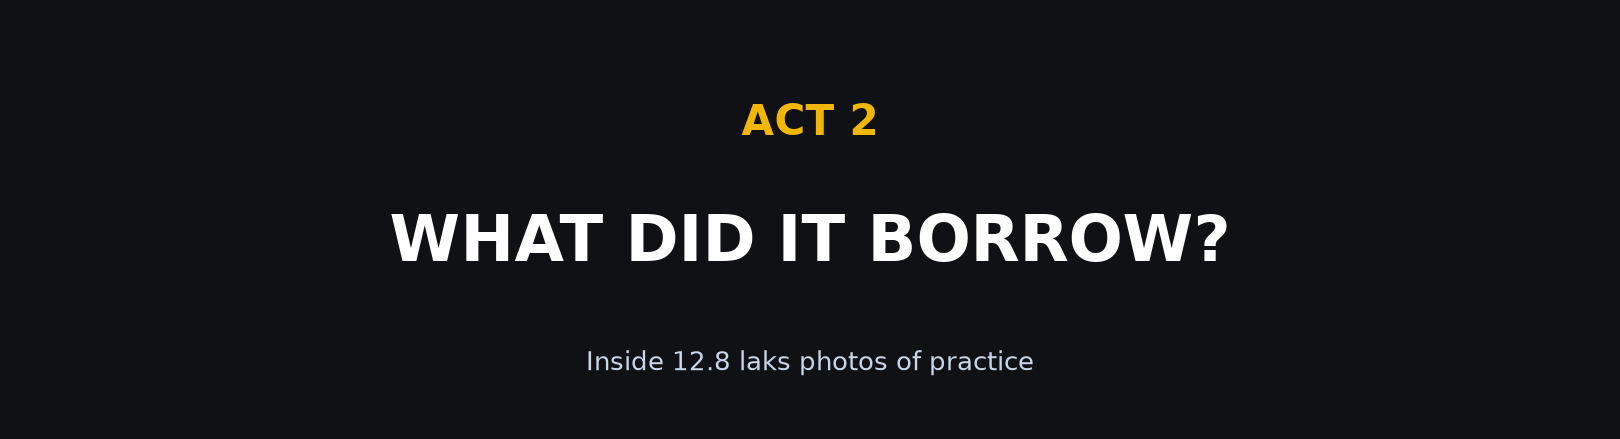

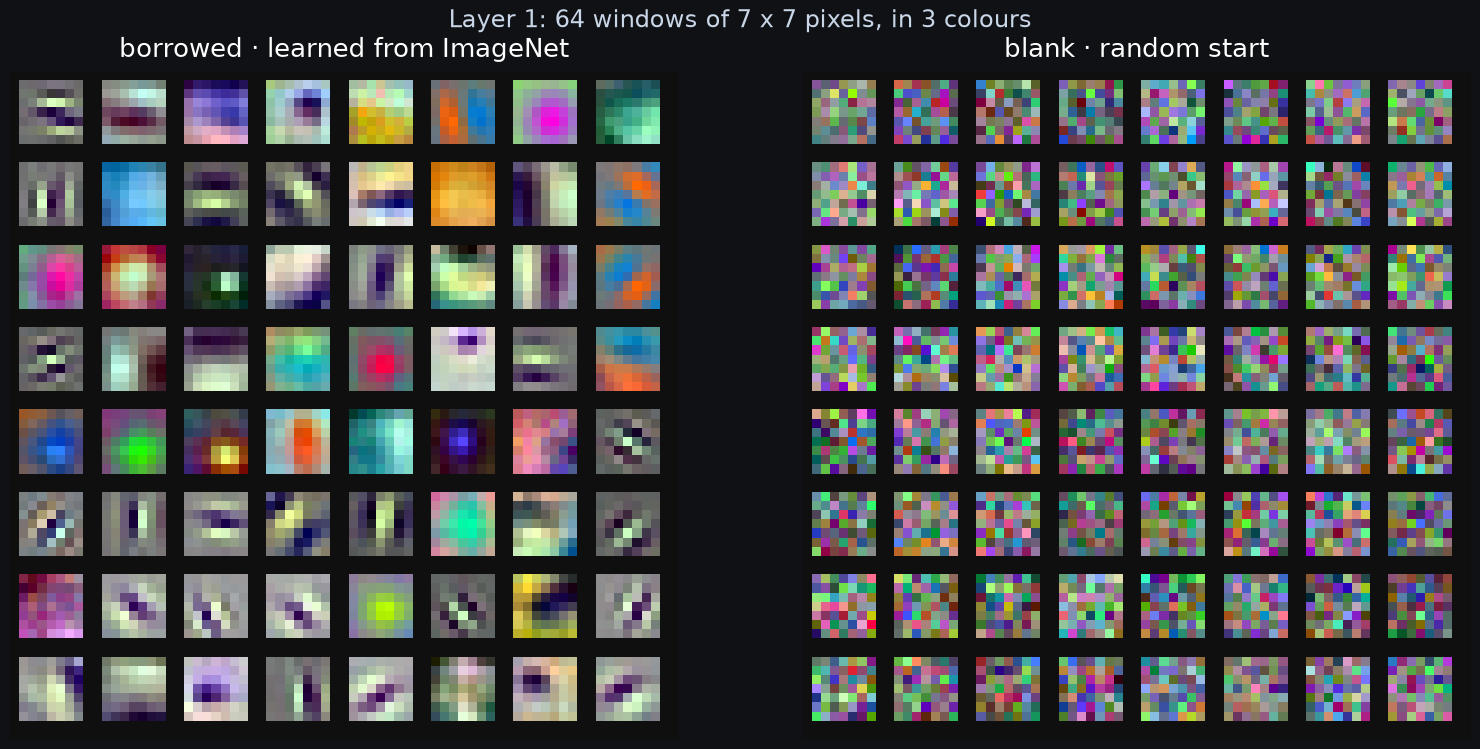

In [17]:
viz.act(2, "What did it borrow?",
        "Inside 12.8 laks photos of practice")
torch.manual_seed(42)
viz.show_filters(imagenet.conv1.weight, blank_brain()[1].conv1.weight)

### 14 · One photo through the brain
Chat's photo from cell 6, through the four stages. Each stage makes more maps, each one smaller.

[(64, 28, 28), (128, 14, 14), (256, 7, 7), (512, 4, 4)]


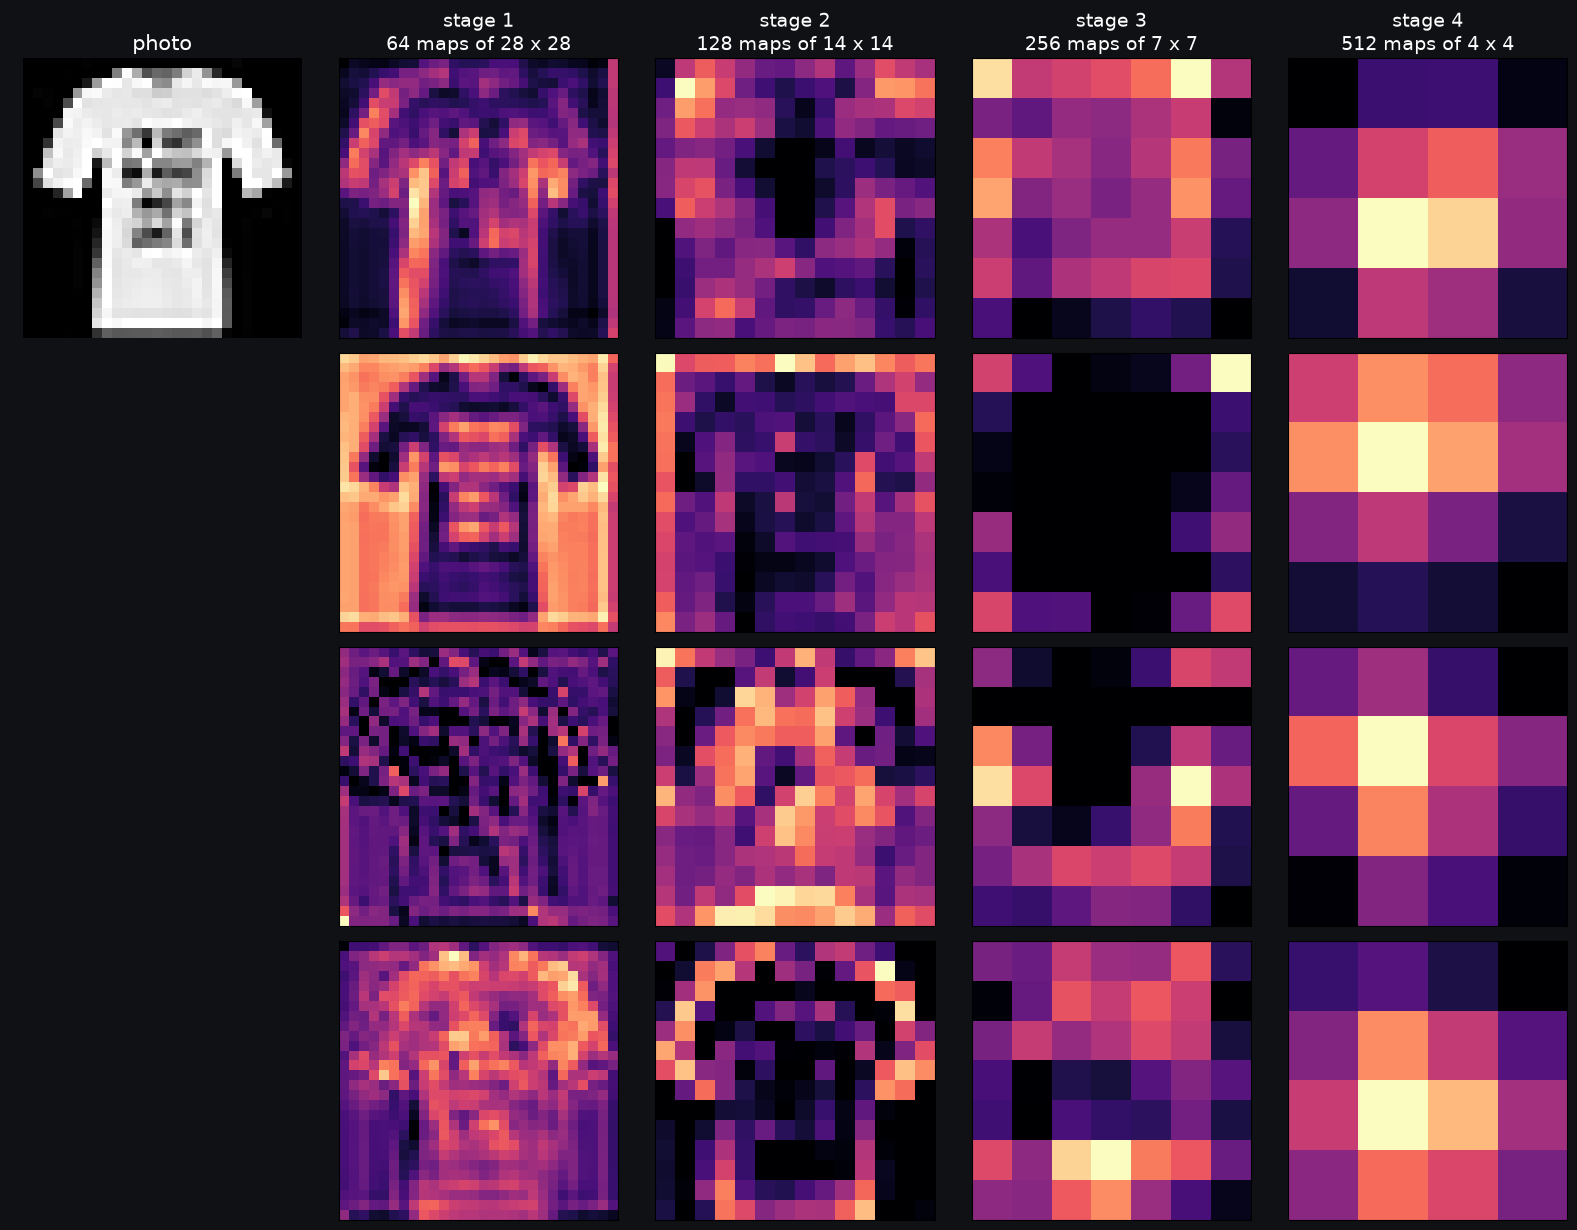

In [18]:
with torch.no_grad():
    h = to_imagenet(X_val[i:i + 1]).to(device)   # chat's photo again
    for part in (imagenet.conv1, imagenet.bn1, imagenet.relu,
                 imagenet.maxpool):
        h = part(h)                        # the start: 112 -> 28 pixels
    maps = []
    for stage in (imagenet.layer1, imagenet.layer2, imagenet.layer3,
                  imagenet.layer4):
        h = stage(h)                       # more maps, each one smaller
        maps.append(h)
print([tuple(m.shape[1:]) for m in maps])
viz.show_stages(X_val[i], maps,
                ["stage 1", "stage 2", "stage 3", "stage 4"])

### 15 · The fingerprint
Cut the head off: every photo becomes 512 numbers. The brain never studies here, so these numbers never change. Every photo once, for the borrowed brain and for a blank one.

In [19]:
def fingerprinter(weights):                # the brain without its head
    body = models.resnet18(weights=weights)
    body.fc = nn.Identity()                # stop at the 512 numbers
    return nn.Sequential(to_imagenet, body).to(device).eval()

def fingerprints(model, X):                # 512 numbers per photo
    out = []
    with torch.no_grad():
        for k in range(0, len(X), 500):
            out.append(model(X[k:k + 500].to(device)).cpu())
    return torch.cat(out)

torch.manual_seed(42)
prints = {}
for name, weights in [("borrowed", "IMAGENET1K_V1"), ("blank", None)]:
    maker = fingerprinter(weights)
    prints[name] = [fingerprints(maker, part)
                    for part in (X_train, X_val, X_test)]
print(prints["borrowed"][0].shape, prints["borrowed"][0][0, :4])

torch.Size([50000, 512]) tensor([0.6442, 0.0000, 0.9278, 0.5605])


### 16 · Freeze the brain, train only a head
A new head (512 numbers in, 10 shelves out) studies the fingerprints of all 50,000 practice photos, 3 epochs. The same head, the same start, for both brains.

**Guess first:** how many of the 11 million knobs learn?

mock test, board exam: {'borrowed': (0.876, 0.877), 'blank': (0.74, 0.735)} | knobs that learn: 5130


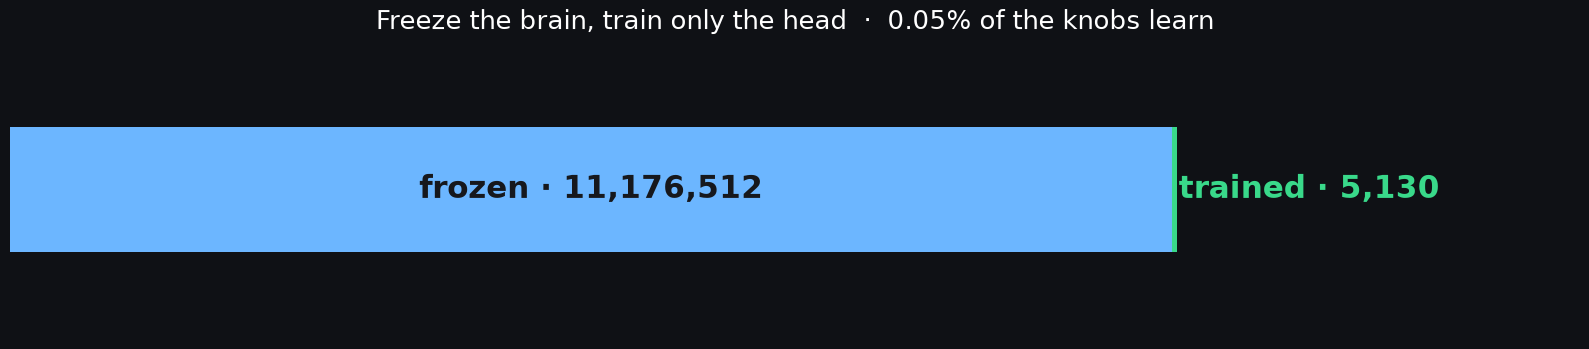

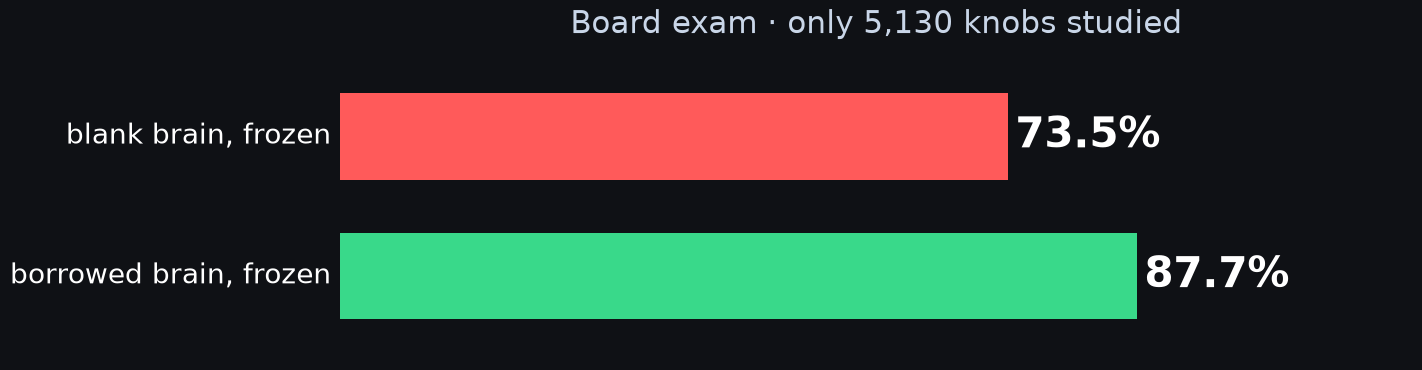

In [20]:
def head_study(F, epochs=3):               # only the head's knobs learn
    torch.manual_seed(42)
    head = nn.Linear(512, 10).to(device)
    optimizer = torch.optim.Adam(head.parameters(), lr=0.001)
    loader = DataLoader(TensorDataset(F, y_train), batch_size=64,
                        shuffle=True)
    for epoch in range(epochs):
        for fb, yb in loader:
            loss = loss_fn(head(fb.to(device)), yb.to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    return head

def head_accuracy(head, F, y):
    with torch.no_grad():
        guess = head(F.to(device)).argmax(dim=1).cpu()
    return round((guess == y).float().mean().item(), 3)

frozen = {}
for name, (F_train, F_val, F_test) in prints.items():
    head = head_study(F_train)
    frozen[name] = (head_accuracy(head, F_val, y_val),
                    head_accuracy(head, F_test, y_test))
trained = sum(p.numel() for p in head.parameters())
print("mock test, board exam:", frozen, "| knobs that learn:", trained)
viz.show_knobs(knobs - trained, trained)
viz.reveal_board(
    [("blank brain, frozen", frozen["blank"][1], viz.HOT),
     ("borrowed brain, frozen", frozen["borrowed"][1], viz.NEON)],
    f"Board exam · only {trained:,} knobs studied")

## Act 3 · The research lab: 5 silent mistakes

### 17 · The lab's shop, and the healthy recipe
1,000 photos, 100 per shelf. The borrowed brain studies everything with small steps: the recipe from cell 11.

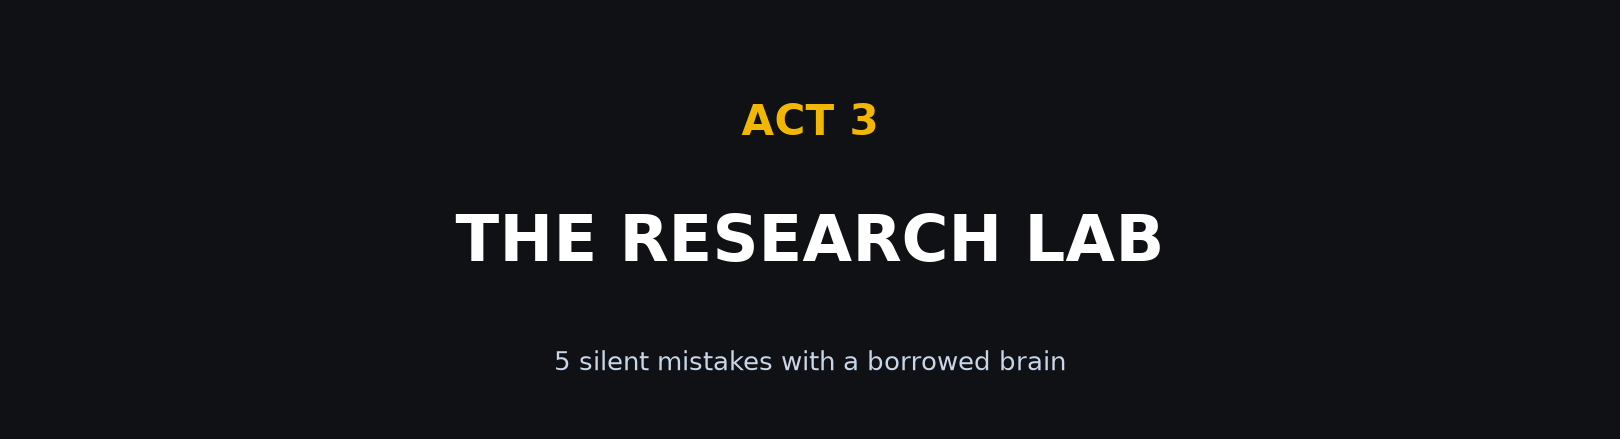

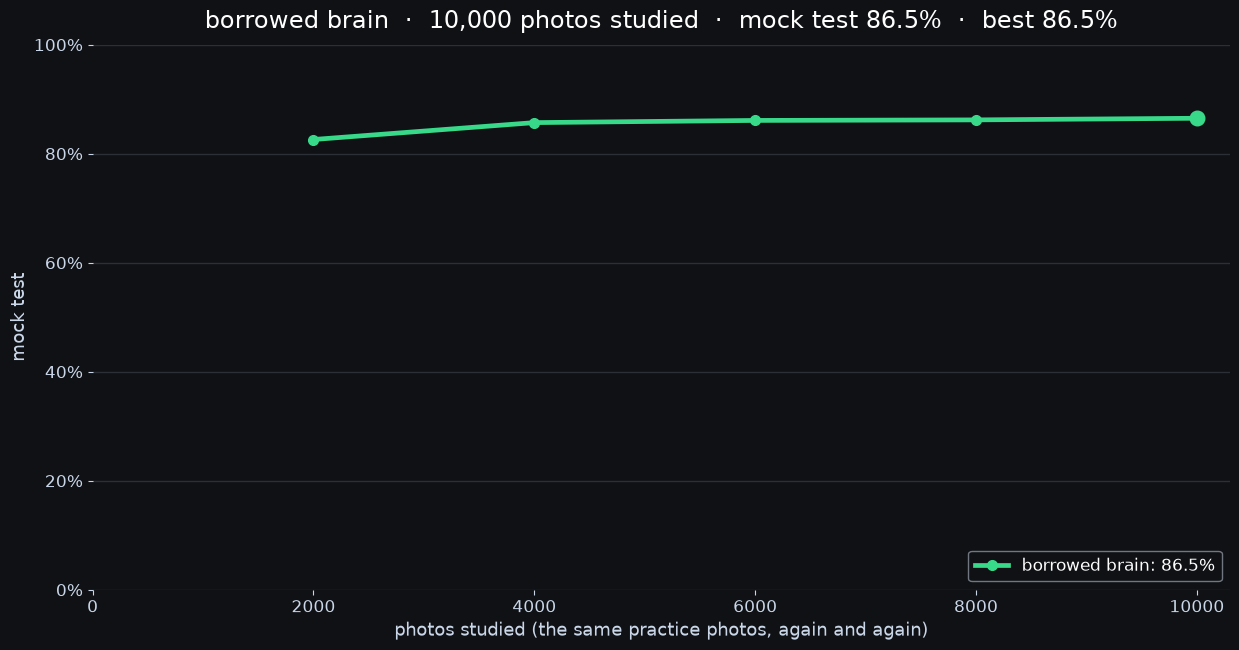

healthy · best mock test: 0.865


In [21]:
viz.act(3, "The research lab",
        "5 silent mistakes with a borrowed brain")
X_lab, y_lab = shop(100)                   # 1,000 photos, 100 per shelf
viz.new_race()                             # a fresh chart for the lab
torch.manual_seed(42)
healthy_brain = borrowed_brain()
healthy_ft = study(healthy_brain, "borrowed brain", X_lab, y_lab,
                   epochs=10, every=32)
print("healthy · best mock test:", max(healthy_ft))

### 18 · Mistake 1: the old head stays
The same recipe with one line missing: the new head. Our shelves 0 to 9 are now ImageNet's shelves 0 to 9.

**Guess first:** before studying, how many of 10,000 does it get right?

before studying: 0.116


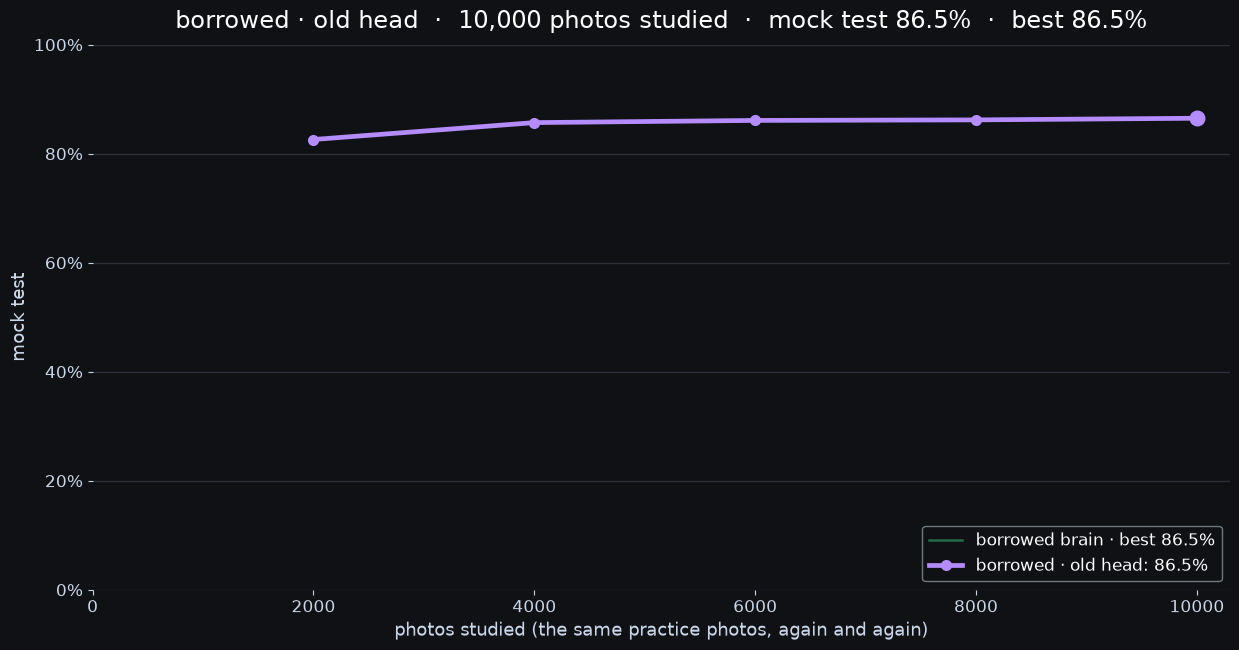

best mock test: 0.865 | answers that aren't our shelves: 0
our shelves, by their old names: ['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead', 'electric ray', 'stingray', 'cock', 'hen', 'ostrich']


In [23]:
torch.manual_seed(42)
body = models.resnet18(weights="IMAGENET1K_V1")
body.fc = nn.Linear(512, 10)             # the missing line
old_head = nn.Sequential(to_imagenet, body).to(device)
old_start = accuracy(old_head, X_val, y_val)
print("before studying:", old_start)
old_head_curve = study(old_head, "borrowed · old head", X_lab, y_lab,
                       epochs=10, every=32)
odd = picks(old_head, X_val)
print("best mock test:", max(old_head_curve),
      "| answers that aren't our shelves:", int((odd > 9).sum()))
print("our shelves, by their old names:", names[:10])

### 19 · Mistake 2: big steps
`lr=0.01`, a hundred times bigger, on the borrowed brain. And the blank brain with the healthy recipe, for comparison.

**The poll:** big steps on a borrowed brain: better or worse than a blank brain?

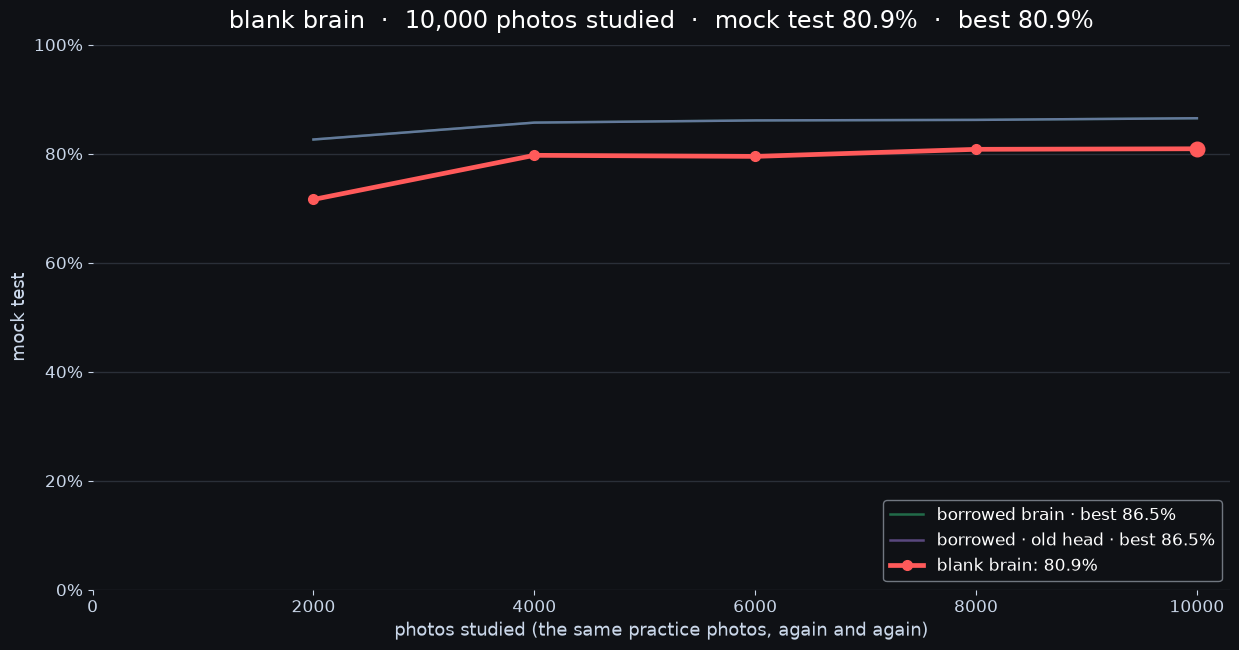

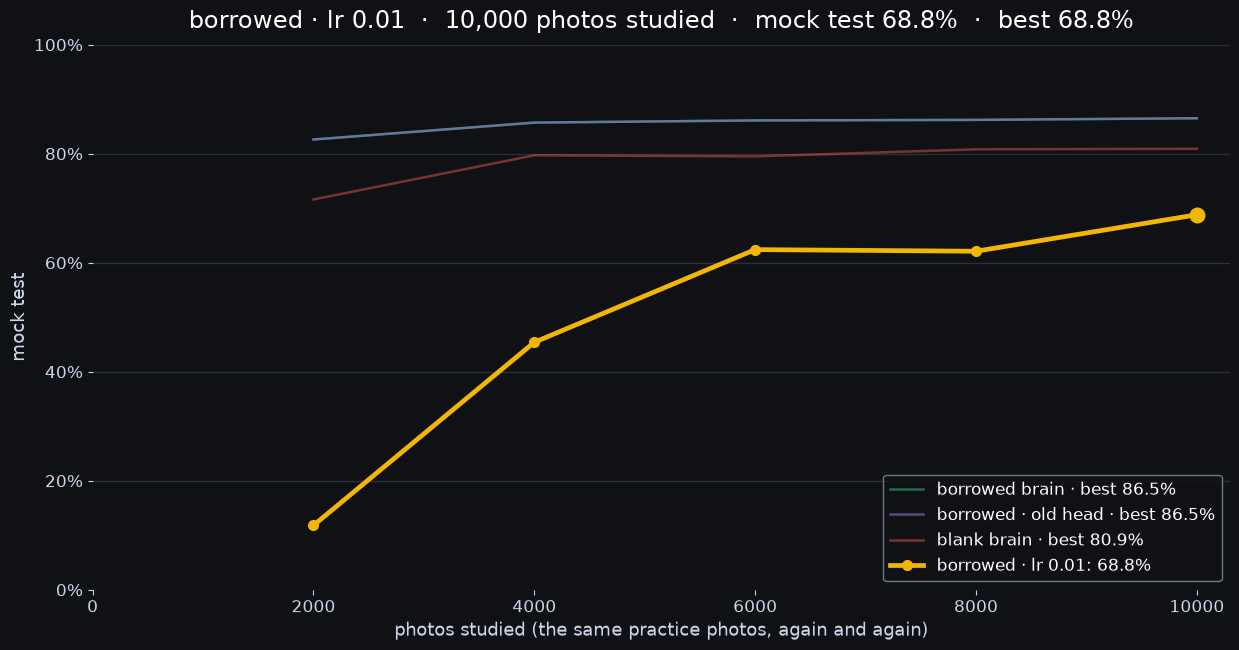

best mock test · borrowed, lr 0.0001: 0.865 | blank: 0.809 | borrowed, lr 0.01: 0.688


In [24]:
torch.manual_seed(42)
blank_lab = study(blank_brain(), "blank brain", X_lab, y_lab,
                  epochs=10, every=32)
torch.manual_seed(42)
hasty = borrowed_brain()
big_steps = study(hasty, "borrowed · lr 0.01", X_lab, y_lab,
                  epochs=10, lr=0.01, every=32)   # the mistake
print("best mock test · borrowed, lr 0.0001:", max(healthy_ft),
      "| blank:", max(blank_lab), "| borrowed, lr 0.01:", max(big_steps))

### 20 · The frozen recipe
Freeze every knob, then a new head. Only the head studies, and the frozen brain stays in exam mode.

In [25]:
def lab_model(adapter=to_imagenet):        # a frozen brain + a new head
    body = models.resnet18(weights="IMAGENET1K_V1")
    for p in body.parameters():
        p.requires_grad = False            # freeze every knob
    body.fc = nn.Linear(512, 10)           # new knobs: only these learn
    return nn.Sequential(adapter, body).to(device)

def lab_study(model, optimizer, epochs=10, mode="exam"):
    loader = DataLoader(TensorDataset(X_lab, y_lab), batch_size=64,
                        shuffle=True)
    scores = []
    for epoch in range(1, epochs + 1):
        for xb, yb in loader:
            if mode == "exam":
                model.eval()               # frozen brain: exam mode
            else:
                model.train()
            loss = loss_fn(model(xb.to(device)), yb.to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        if epoch % 2 == 0:                 # a mock test every 2 epochs
            scores.append(accuracy(model, X_val, y_val))
    return scores

torch.manual_seed(42)
healthy_model = lab_model()
optimizer = torch.optim.Adam(healthy_model[1].fc.parameters(), lr=0.001)
healthy = lab_study(healthy_model, optimizer)
print("frozen + new head · mock test every 2 epochs:", healthy)

frozen + new head · mock test every 2 epochs: [0.756, 0.79, 0.807, 0.808, 0.817]


### 21 · Mistake 3: the optimizer comes first
The same steps, in a different order: the optimizer is made **before** the new head.

**Guess first:** any error? Any learning?

mock test every 2 epochs: [0.116, 0.116, 0.116, 0.116, 0.116]


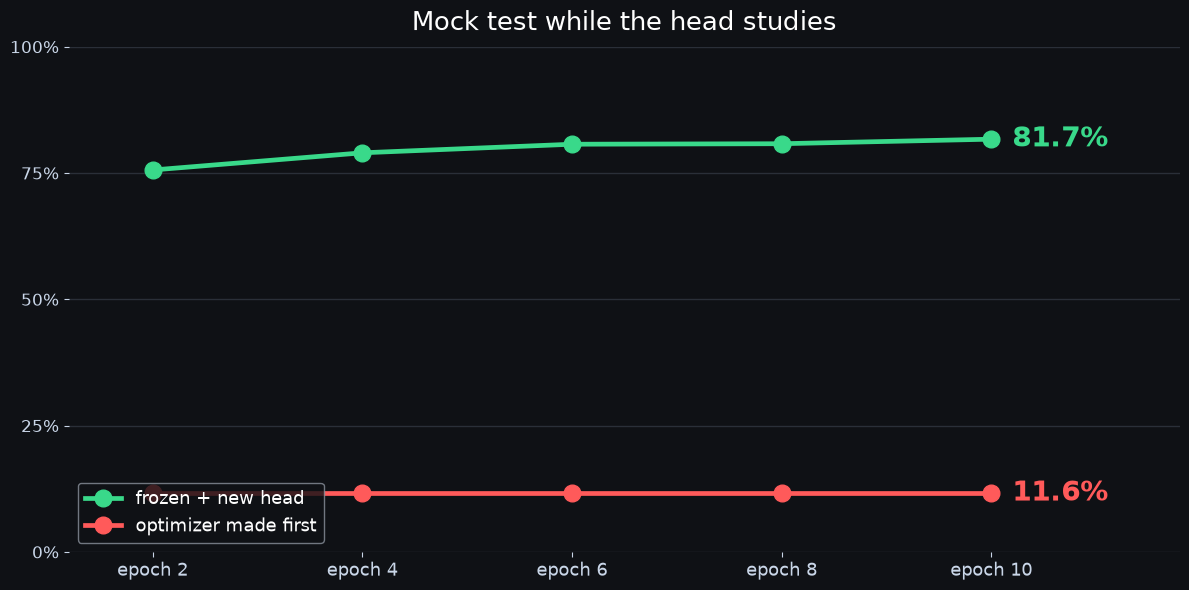

In [26]:
torch.manual_seed(42)
body = models.resnet18(weights="IMAGENET1K_V1")
for p in body.parameters():
    p.requires_grad = False
optimizer = torch.optim.Adam(body.fc.parameters(), lr=0.001)  # too early
body.fc = nn.Linear(512, 10)               # the new head, made after
early = nn.Sequential(to_imagenet, body).to(device)
stuck = lab_study(early, optimizer)
print("mock test every 2 epochs:", stuck)
viz.show_epochs({"frozen + new head": healthy,
                 "optimizer made first": stuck}, every=2)

### 22 · Mistake 4: a frozen brain in study mode
`requires_grad = False` stops the knobs. Does it stop everything? Same recipe, but `model.train()`.

**Guess first:** after studying, how many numbers inside the frozen brain changed?

mock test every 2 epochs: [0.588, 0.733, 0.762, 0.766, 0.775]
averages changed: 9,600 of 9,600


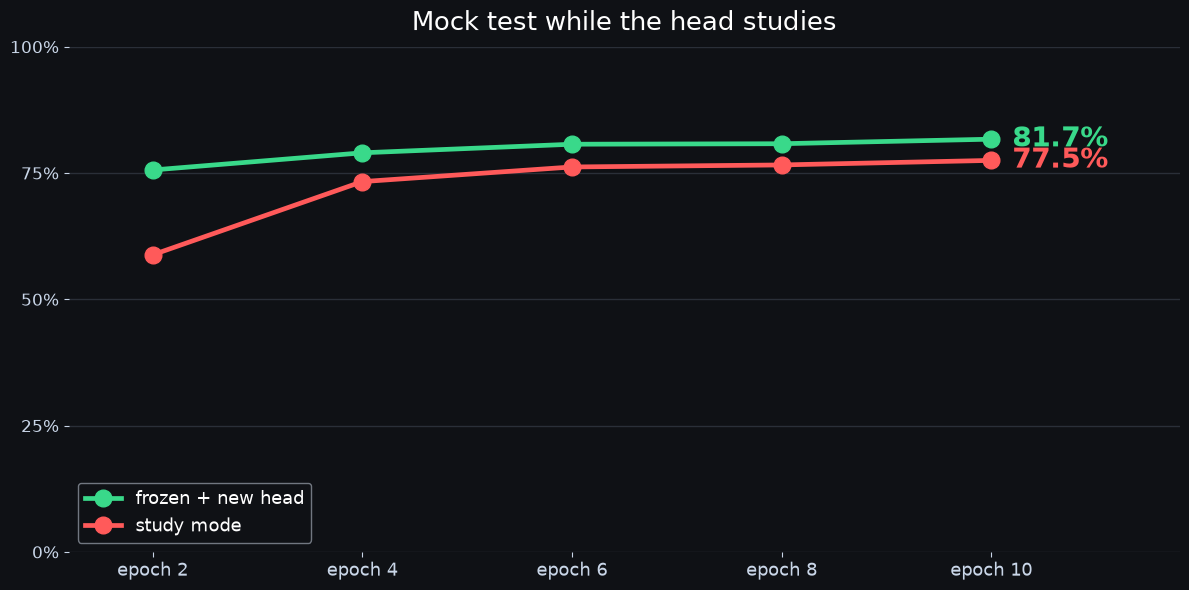

In [27]:
torch.manual_seed(42)
loose = lab_model()
before = [b.clone() for n, b in loose[1].named_buffers()
          if "running" in n]               # BatchNorm's averages
optimizer = torch.optim.Adam(loose[1].fc.parameters(), lr=0.001)
drift = lab_study(loose, optimizer, mode="study")   # the mistake
after = [b for n, b in loose[1].named_buffers() if "running" in n]
changed = sum(int((a != b).sum()) for a, b in zip(after, before))
total = sum(b.numel() for b in before)
print("mock test every 2 epochs:", drift)
print(f"averages changed: {changed:,} of {total:,}")
viz.show_epochs({"frozen + new head": healthy, "study mode": drift},
                every=2)

### 23 · Mistake 5: no resize
The adapter without `v2.Resize`: 28 x 28 photos go straight in.

**Guess first:** error, or not?

mock test every 2 epochs: [0.67, 0.701, 0.718, 0.731, 0.74]


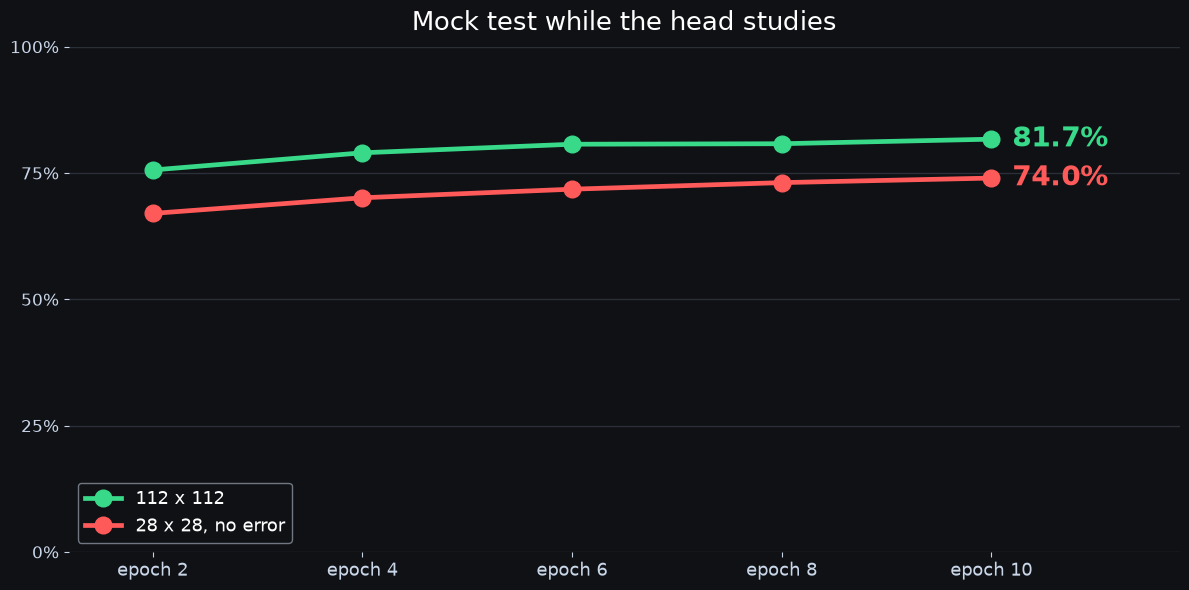

In [28]:
no_resize = nn.Sequential(v2.Lambda(flip), v2.RGB(),
                          v2.Normalize(MEAN, STD))   # no v2.Resize
torch.manual_seed(42)
tiny = lab_model(adapter=no_resize)
optimizer = torch.optim.Adam(tiny[1].fc.parameters(), lr=0.001)
small = lab_study(tiny, optimizer)
print("mock test every 2 epochs:", small)
viz.show_epochs({"112 x 112": healthy, "28 x 28, no error": small},
                every=2)

### 24 · The checklist

In [ ]:
viz.checklist(["model.fc = nn.Linear(512, 10): our shelves",
               "a borrowed brain gets small steps: lr=0.0001",
               "make the optimizer after the new head",
               "frozen brain: model.eval() while the head studies",
               "v2.Resize(112): a size it can see"])

## Practice
1. Cell 6: pick one photo from each shelf. Which of our shelves does ImageNet know best?
2. Cell 11: give the blank brain `lr=0.001`, the steps from Episodes 7 to 10. Better or worse?
3. Cell 16: train the head for 10 epochs instead of 3. How close does it get to cell 11's borrowed brain?
4. Cell 20: unfreeze the last stage too (`for p in body.layer4.parameters(): p.requires_grad = True`) and give the optimizer those knobs as well. What happens?
5. Cell 23: try `v2.Resize(56)`, half the size. Where does it land between 28 and 112?